# Customer Churn Analysis

**Problem statement:** Analyse customer data to identify churn patterns and customer segments with higher churn, and recommend retention actions.

**Dataset:** [Telco Customer Churn — Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

Historical segment differences show associations, not causes. Retention recommendations have not been implemented.

## Load data

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

paths = [Path('data/raw/telco_customer_churn.csv'),
         Path('telco_customer_churn.csv'),
         Path('WA_Fn-UseC_-Telco-Customer-Churn.csv')]
data_path = next((p for p in paths if p.exists()), None)

if data_path is None:
    from urllib.request import urlopen
    from zipfile import ZipFile
    from io import BytesIO
    url = 'https://www.kaggle.com/api/v1/datasets/download/blastchar/telco-customer-churn'
    with urlopen(url, timeout=60) as response:
        archive = ZipFile(BytesIO(response.read()))
    filename = next(name for name in archive.namelist() if name.endswith('.csv'))
    data_path = Path('telco_customer_churn.csv')
    data_path.write_bytes(archive.read(filename))

df = pd.read_csv(data_path)
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
display(pd.DataFrame({'Rows': [df.shape[0]], 'Columns': [df.shape[1]]}))
display(pd.DataFrame({'DataType': df.dtypes.astype(str), 'MissingValues': df.isna().sum()}))

,Rows,Columns
0,7043,21


,DataType,MissingValues
customerID,object,0
gender,object,0
SeniorCitizen,int64,0
Partner,object,0
Dependents,object,0
tenure,int64,0
PhoneService,object,0
MultipleLines,object,0
InternetService,object,0
OnlineSecurity,object,0


## Clean data

In [3]:
for col in df.select_dtypes(include='object'):
    df[col] = df[col].str.strip()

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

display(pd.DataFrame({
    'Check': ['Duplicate rows', 'Duplicate customer IDs', 'Missing TotalCharges'],
    'Count': [df.duplicated().sum(), df.customerID.duplicated().sum(), df.TotalCharges.isna().sum()]
}))
display(df.loc[df.TotalCharges.isna(), ['customerID', 'tenure', 'TotalCharges']])

,Check,Count
0,Duplicate rows,0
1,Duplicate customer IDs,0
2,Missing TotalCharges,11


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,NaN
753,3115-CZMZD,0,NaN
936,5709-LVOEQ,0,NaN
1082,4367-NUYAO,0,NaN
1340,1371-DWPAZ,0,NaN
3331,7644-OMVMY,0,NaN
3826,3213-VVOLG,0,NaN
4380,2520-SGTTA,0,NaN
5218,2923-ARZLG,0,NaN
6670,4075-WKNIU,0,NaN


Blank TotalCharges values are kept as missing. No customer records are removed.

In [4]:
assert df.customerID.is_unique
assert df.Churn.isin(['Yes', 'No']).all()

df['ChurnFlag'] = df.Churn.eq('Yes').astype(int)
df['TenureGroup'] = pd.cut(df.tenure, [-1, 12, 24, 48, 72],
                          labels=['0–12', '13–24', '25–48', '49–72'])
df.to_csv('customers_clean.csv', index=False)
display(df[['customerID', 'tenure', 'TenureGroup', 'Churn', 'ChurnFlag']].head())

,customerID,tenure,TenureGroup,Churn,ChurnFlag
0,7590-VHVEG,1,0–12,No,0
1,5575-GNVDE,34,25–48,No,0
2,3668-QPYBK,2,0–12,Yes,1
3,7795-CFOCW,45,25–48,No,0
4,9237-HQITU,2,0–12,Yes,1


## Churn summary

In [5]:
summary = pd.DataFrame({
    'Customers': [len(df)],
    'ChurnedCustomers': [df.ChurnFlag.sum()],
    'ChurnRatePct': [round(df.ChurnFlag.mean() * 100, 2)],
    'AverageMonthlyCharge': [round(df.MonthlyCharges.mean(), 2)],
    'AverageTenureMonths': [round(df.tenure.mean(), 2)]
})
display(summary)

,Customers,ChurnedCustomers,ChurnRatePct,AverageMonthlyCharge,AverageTenureMonths
0,7043,1869,26.54,64.76,32.37


## SQL analysis

In [6]:
conn = sqlite3.connect(':memory:')
df.to_sql('customers', conn, index=False, if_exists='replace')
display(pd.read_sql_query('SELECT COUNT(*) AS customers FROM customers', conn))

,customers
0,7043


### Contract type

In [7]:
query = """
SELECT Contract,
       COUNT(*) AS customers,
       SUM(ChurnFlag) AS churned_customers,
       ROUND(100.0 * AVG(ChurnFlag), 2) AS churn_rate_pct
FROM customers
GROUP BY Contract
ORDER BY churn_rate_pct DESC;
"""
contract_summary = pd.read_sql_query(query, conn)
display(contract_summary)

,Contract,customers,churned_customers,churn_rate_pct
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


### Tenure in months

In [8]:
query = """
SELECT TenureGroup,
       COUNT(*) AS customers,
       SUM(ChurnFlag) AS churned_customers,
       ROUND(100.0 * AVG(ChurnFlag), 2) AS churn_rate_pct
FROM customers
GROUP BY TenureGroup
ORDER BY churn_rate_pct DESC;
"""
tenuregroup_summary = pd.read_sql_query(query, conn)
display(tenuregroup_summary)

,TenureGroup,customers,churned_customers,churn_rate_pct
0,0–12,2186,1037,47.44
1,13–24,1024,294,28.71
2,25–48,1594,325,20.39
3,49–72,2239,213,9.51


### Payment method

In [9]:
query = """
SELECT PaymentMethod,
       COUNT(*) AS customers,
       SUM(ChurnFlag) AS churned_customers,
       ROUND(100.0 * AVG(ChurnFlag), 2) AS churn_rate_pct
FROM customers
GROUP BY PaymentMethod
ORDER BY churn_rate_pct DESC;
"""
paymentmethod_summary = pd.read_sql_query(query, conn)
display(paymentmethod_summary)

,PaymentMethod,customers,churned_customers,churn_rate_pct
0,Electronic check,2365,1071,45.29
1,Mailed check,1612,308,19.11
2,Bank transfer (automatic),1544,258,16.71
3,Credit card (automatic),1522,232,15.24


### Internet service

In [10]:
query = """
SELECT InternetService,
       COUNT(*) AS customers,
       SUM(ChurnFlag) AS churned_customers,
       ROUND(100.0 * AVG(ChurnFlag), 2) AS churn_rate_pct
FROM customers
GROUP BY InternetService
ORDER BY churn_rate_pct DESC;
"""
internetservice_summary = pd.read_sql_query(query, conn)
display(internetservice_summary)

,InternetService,customers,churned_customers,churn_rate_pct
0,Fiber optic,3096,1297,41.89
1,DSL,2421,459,18.96
2,No,1526,113,7.40


### Technical support

In [11]:
query = """
SELECT TechSupport,
       COUNT(*) AS customers,
       SUM(ChurnFlag) AS churned_customers,
       ROUND(100.0 * AVG(ChurnFlag), 2) AS churn_rate_pct
FROM customers
GROUP BY TechSupport
ORDER BY churn_rate_pct DESC;
"""
techsupport_summary = pd.read_sql_query(query, conn)
display(techsupport_summary)

,TechSupport,customers,churned_customers,churn_rate_pct
0,No,3473,1446,41.64
1,Yes,2044,310,15.17
2,No internet service,1526,113,7.40


### Combined customer segments

In [12]:
query = """
SELECT Contract, TenureGroup, InternetService,
       COUNT(*) AS customers,
       SUM(ChurnFlag) AS churned_customers,
       ROUND(100.0 * AVG(ChurnFlag), 2) AS churn_rate_pct
FROM customers
GROUP BY Contract, TenureGroup, InternetService
HAVING COUNT(*) >= 100
ORDER BY churn_rate_pct DESC;
"""
segments = pd.read_sql_query(query, conn)
display(segments)

,Contract,TenureGroup,InternetService,customers,churned_customers,churn_rate_pct
0,Month-to-month,0–12,Fiber optic,916,643,70.20
1,Month-to-month,13–24,Fiber optic,425,215,50.59
2,Month-to-month,25–48,Fiber optic,521,226,43.38
3,Month-to-month,0–12,DSL,690,293,42.46
4,Month-to-month,49–72,Fiber optic,266,78,29.32
5,Month-to-month,13–24,DSL,232,55,23.71
6,Month-to-month,0–12,No,388,88,22.68
7,One year,25–48,Fiber optic,154,31,20.13
8,One year,49–72,Fiber optic,355,67,18.87
9,Month-to-month,25–48,DSL,227,36,15.86


### Payment methods within each contract type

In [13]:
query = """
SELECT Contract, PaymentMethod,
       COUNT(*) AS customers,
       ROUND(100.0 * AVG(ChurnFlag), 2) AS churn_rate_pct
FROM customers
GROUP BY Contract, PaymentMethod
HAVING COUNT(*) >= 30
ORDER BY Contract, churn_rate_pct DESC;
"""
display(pd.read_sql_query(query, conn))

,Contract,PaymentMethod,customers,churn_rate_pct
0,Month-to-month,Electronic check,1850,53.73
1,Month-to-month,Bank transfer (automatic),589,34.13
2,Month-to-month,Credit card (automatic),543,32.78
3,Month-to-month,Mailed check,893,31.58
4,One year,Electronic check,347,18.44
5,One year,Credit card (automatic),398,10.30
6,One year,Bank transfer (automatic),391,9.72
7,One year,Mailed check,337,6.82
8,Two year,Electronic check,168,7.74
9,Two year,Bank transfer (automatic),564,3.37


## Charts

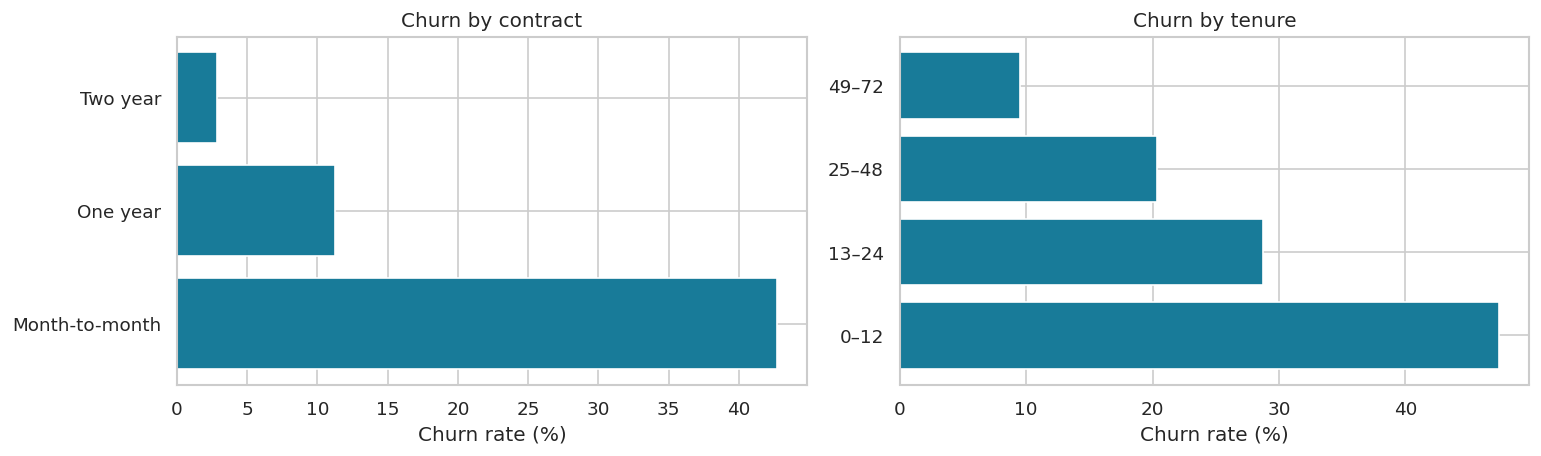

In [14]:
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, table, column, title in [
    (axes[0], contract_summary, 'Contract', 'Churn by contract'),
    (axes[1], tenuregroup_summary, 'TenureGroup', 'Churn by tenure')
]:
    ax.barh(table[column], table.churn_rate_pct, color='#187b99')
    ax.set_xlabel('Churn rate (%)')
    ax.set_title(title)
fig.tight_layout()
plt.show()

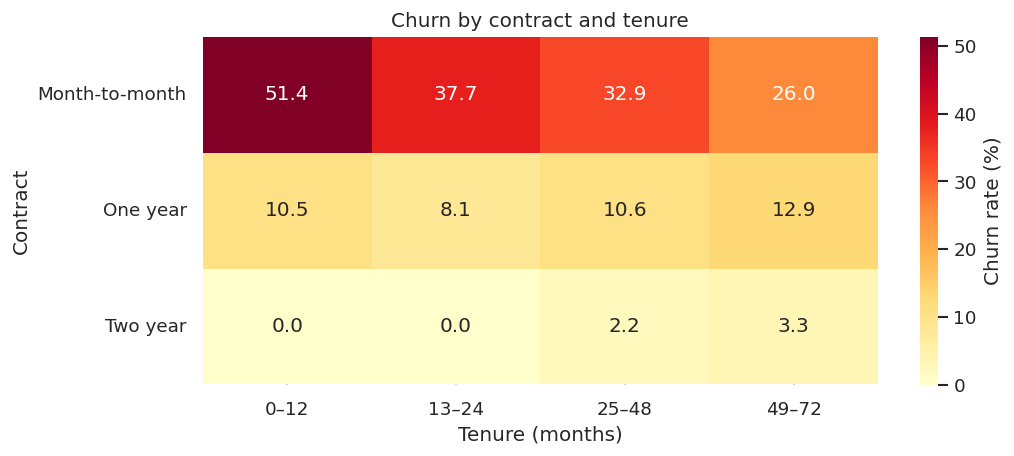

In [15]:
matrix = df.pivot_table(index='Contract', columns='TenureGroup',
                        values='ChurnFlag', aggfunc='mean', observed=True) * 100
plt.figure(figsize=(9, 4))
sns.heatmap(matrix, annot=True, fmt='.1f', cmap='YlOrRd',
            cbar_kws={'label': 'Churn rate (%)'})
plt.title('Churn by contract and tenure')
plt.xlabel('Tenure (months)')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Findings and recommendations

In [16]:
findings = pd.DataFrame([
    ['Overall churn', f"{summary.ChurnRatePct.iloc[0]:.2f}%", 'Use as the sample baseline'],
    ['Month-to-month contracts', f"{contract_summary.loc[contract_summary.Contract.eq('Month-to-month'), 'churn_rate_pct'].iloc[0]:.2f}%", 'Test optional longer-term plan incentives'],
    ['Tenure up to 12 months', f"{tenuregroup_summary.loc[tenuregroup_summary.TenureGroup.eq('0–12'), 'churn_rate_pct'].iloc[0]:.2f}%", 'Test onboarding support and early service check-ins'],
    ['Electronic check', f"{paymentmethod_summary.loc[paymentmethod_summary.PaymentMethod.eq('Electronic check'), 'churn_rate_pct'].iloc[0]:.2f}%", 'Investigate billing issues before testing payment assistance']
], columns=['Segment', 'ObservedChurnRate', 'Recommendation'])
display(findings)
conn.close()

,Segment,ObservedChurnRate,Recommendation
0,Overall churn,26.54%,Use as the sample baseline
1,Month-to-month contracts,42.71%,Test optional longer-term plan incentives
2,Tenure up to 12 months,47.44%,Test onboarding support and early service chec...
3,Electronic check,45.29%,Investigate billing issues before testing paym...
